# HW5 데이터 전처리와 분석

In [1]:
import platform
import pandas as pd
import matplotlib.pyplot as plt

fonts = {"Windows": "Malgun Gothic", "Darwin": "AppleGothic"}
plt.rcParams["font.family"] = fonts.get(platform.system(), "NanumGothic")
plt.rcParams["axes.unicode_minus"] = False

df = pd.read_csv("sales_data.csv")

dates = ["order_date", "shipping_date", "delivery_date"]
for col in dates:
    df[col] = pd.to_datetime(df[col])

print(df.shape)

(1030, 14)


In [2]:
before = len(df)
df = df.drop_duplicates()

print(before, "->", len(df))

1030 -> 1004


In [3]:
bad = df["quantity"] > 100

df.loc[bad, "quantity"] = (
    df.loc[bad, "total_sales"] / df.loc[bad, "unit_price"]
).round().astype(int)

diff = (df["total_sales"] - df["quantity"] * df["unit_price"]).abs()

print("고친 줄 :", bad.sum())
print("수량 최대 :", df["quantity"].max())
print("총액 안 맞는 줄 :", (diff > 1).sum())

고친 줄 : 22
수량 최대 : 99
총액 안 맞는 줄 : 0


In [4]:
df["date_error"] = df["delivery_date"] < df["shipping_date"]

df.to_csv("sales_clean.csv", index=False)

print("날짜 오류 :", df["date_error"].sum())
print("저장한 데이터 크기 :", df.shape)

날짜 오류 : 147
저장한 데이터 크기 : (1004, 15)


## ⑤ 배송 기간은 보통 며칠인가?

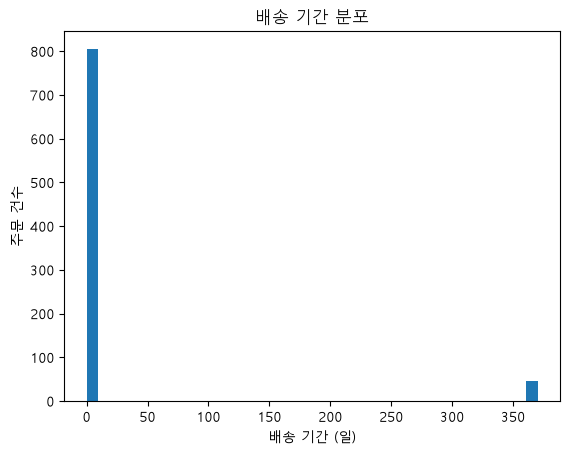

분석 건수 : 852
평균 : 22.05
중앙값 : 2.0


In [5]:
valid = df.loc[~df["date_error"]]
days = (valid["delivery_date"] - valid["shipping_date"]).dt.days.dropna()

days.plot.hist(bins=40, title="배송 기간 분포")
plt.xlabel("배송 기간 (일)")
plt.ylabel("주문 건수")
plt.show()

print("분석 건수 :", len(days))
print("평균 :", round(days.mean(), 2))
print("중앙값 :", days.median())

In [6]:
long_days = days[days > 300]
usual_days = days[days <= 300]

print("300일 초과 건수 :", len(long_days))
print("범위 :", long_days.min(), "~", long_days.max(), "일")
print("제외 후 평균 :", round(usual_days.mean(), 2))
print("제외 후 중앙값 :", usual_days.median())

300일 초과 건수 : 47
범위 : 364.0 ~ 370.0 일
제외 후 평균 : 1.93
제외 후 중앙값 : 2.0


전체 평균은 22.05일, 중앙값은 2일이다. 364~370일인 47건이 평균을 크게 끌어올렸다.
나머지는 0~5일에 모여 있어 300일 초과 건은 일반적인 배송 기간을 요약할 때만 제외했다. 제외 후 평균은 1.93일, 중앙값은 2일이다.

## ⑥ 만족도가 낮을수록 반품이 많은가?

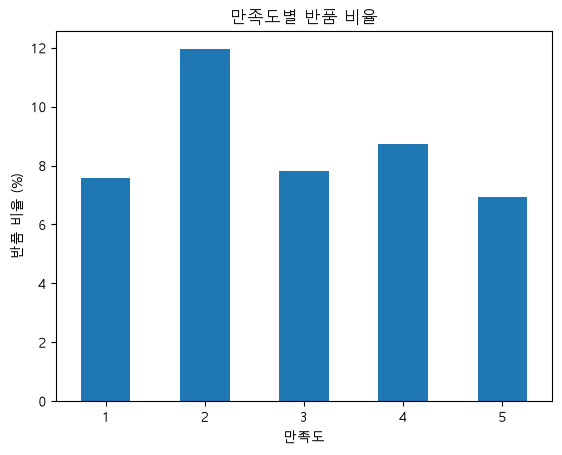

satisfaction
1     7.59
2    11.96
3     7.81
4     8.72
5     6.93
Name: status, dtype: float64

In [7]:
return_rate = (
    (df["status"] == "반품")
    .groupby(df["satisfaction"])
    .mean() * 100
).reindex([1, 2, 3, 4, 5])

return_rate.plot.bar(title="만족도별 반품 비율", rot=0)
plt.xlabel("만족도")
plt.ylabel("반품 비율 (%)")
plt.show()

return_rate.round(2)

만족도가 낮을수록 반품 비율이 일관되게 높아지지는 않는다. 만족도 1의 반품 비율은 7.59%로, 만족도 2의 11.96%보다 낮다.
만족도 3·4·5의 반품 비율도 각각 7.81%, 8.72%, 6.93%로 점수 순서에 따라 계속 감소하지 않는다.

## ⑦ 매출 1위 카테고리는 건수·단가·수량 중 무엇이 다른가?

In [8]:
category_summary = df.groupby("category").agg(
    주문건수=("total_sales", "size"),
    매출합계=("total_sales", "sum"),
    평균단가=("unit_price", "mean"),
    평균수량=("quantity", "mean")
)

category_summary.sort_values("매출합계", ascending=False).round(2)

,주문건수,매출합계,평균단가,평균수량
category,,,,
가구,213,2.843337e+09,257322.91,51.04
식품,210,2.513274e+09,255232.93,47.31
전자제품,207,2.471628e+09,249651.61,47.96
도서,204,2.453240e+09,238500.64,49.50
의류,170,2.181904e+09,249447.16,51.61


가구는 약 28.43억 원으로 매출 1위이며, 주문 건수 213건과 평균 단가 257,322.91원도 각각 가장 높다.
2위 식품과 비교하면 평균 수량이 51.04개 대 47.31개로, 건수나 평균 단가보다 상대적인 차이가 크다.